*Previous notebook: log loss (cross-entropy) as cost function. — This notebook: L1 and L2 regularization and their geometric intuition.*

# Regularization

Regularization is a technique used to **reduce overfitting (high variance)** by adding a penalty term to the cost function. It discourages the model from learning overly complex patterns by limiting the size of the weights.

---

## Types of Regularization

### L1 Regularization (Lasso)
L1 adds the sum of absolute values of the weights:

$$
||W|| = \sum |w_{i,j}|
$$

- Encourages **sparsity** (many weights become exactly zero)
- Leads to **simpler and smaller models**
- Useful for **feature selection**

---

### L2 Regularization (Ridge)
L2 adds the sum of squared values of the weights (Frobenius norm):

$$
||W||^2 = \sum w_{i,j}^2
$$

For vectors:

$$
||W||^2 = W^T W
$$

- Penalizes large weights more strongly
- Produces **smooth and stable models**
- **Most commonly used** in practice

---

## How it works?

Original cost function:

$$
J(w,b) = \frac{1}{m} \sum L(y^{(i)}, \hat{y}^{(i)})
$$

With **L2 regularization**:

$$
J(w,b) = \frac{1}{m} \sum L(y^{(i)}, \hat{y}^{(i)}) + \frac{\lambda}{2m} \sum w_i^2
$$

With **L1 regularization**:

$$
J(w,b) = \frac{1}{m} \sum L(y^{(i)}, \hat{y}^{(i)}) + \frac{\lambda}{2m} \sum |w_i|
$$

- $\lambda$ is the **regularization parameter** (hyperparameter)
- Higher $\lambda$ → stronger penalty → simpler model

---

### Effect on Gradient Descent (Weight Decay)

With L2 regularization:

$$
dw^{[l]} = \text{(backprop term)} + \frac{\lambda}{m} w^{[l]}
$$

Update rule:

$$
w^{[l]} = w^{[l]} - \alpha \cdot dw^{[l]}
$$

Substituting:

$$
w^{[l]} = (1 - \frac{\alpha \lambda}{m}) w^{[l]} - \alpha \cdot \text{(backprop term)}
$$

This is called **weight decay**:
- Each step slightly shrinks the weights
- Large weights are penalized more

---

## Why does Regularization reduce overfitting?

### Intuition 1 (Model Simplicity)
- If $\lambda$ is **too large** → a lot of weights ≈ 0 → model becomes very simple (almost linear)
- If $\lambda$ is **well chosen** → only unnecessary weights shrink → better generalization

---

### Intuition 2 (Activation Behavior)
With activation functions like **tanh**:
- Small weights → inputs near 0
- tanh behaves **almost linearly** near 0

So:
- Large $\lambda$ → network becomes more **linear**
- This reduces the ability to overfit complex patterns

---

## Practical Tip

When debugging gradient descent with regularization:
- Plot the **new cost function J (including regularization)**
- It should **decrease monotonically** during training

If you plot the old cost (without regularization), it may not decrease properly.

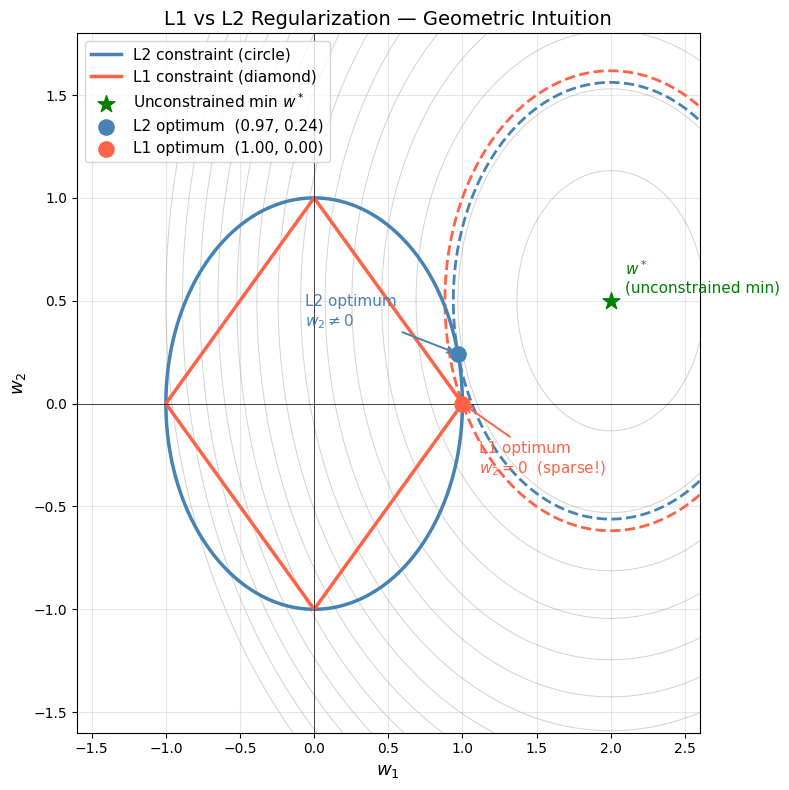

In [1]:
# Visual explanation of L1 vs L2 regularization

import numpy as np
import matplotlib.pyplot as plt

# Unconstrained optimum — sits outside the constraint region
w_star = np.array([2.0, 0.5])

# Cost function: circular contours centred at w_star
w1 = np.linspace(-1.6, 2.6, 400)
w2 = np.linspace(-1.6, 1.8, 400)
W1, W2 = np.meshgrid(w1, w2)
J = (W1 - w_star[0])**2 + (W2 - w_star[1])**2

# Constraint radius
r = 1.0

# --- L2 constraint (circle) ---
theta = np.linspace(0, 2 * np.pi, 500)
l2_x = r * np.cos(theta)
l2_y = r * np.sin(theta)

# L2 optimal: point on circle closest to w_star (projection onto boundary)
# = r * w_star / ||w_star||   =>  approx (0.97, 0.24) — both weights non-zero
l2_point = r * w_star / np.linalg.norm(w_star)

# --- L1 constraint (diamond) ---
l1_vertices = np.array([[r, 0], [0, r], [-r, 0], [0, -r], [r, 0]])

# L1 optimal: corner (r, 0) — verified analytically:
# on the first-quadrant edge  w1 = 1-t, w2 = t,
# dJ/dt = 4t + 1 > 0 for all t >= 0  =>  minimum at t=0, i.e. (1, 0)
# Result: w2 = 0  =>  sparse solution!
l1_point = np.array([r, 0.0])

# Loss value at each tangent point (= level of the touching contour)
j_l2 = float(np.sum((l2_point - w_star) ** 2))
j_l1 = float(np.sum((l1_point - w_star) ** 2))

# --- Plot ---
plt.figure(figsize=(8, 8))

# Background loss contours
plt.contour(W1, W2, J, levels=np.linspace(0.4, 9, 14),
            colors='gray', alpha=0.35, linewidths=0.7)

# Tangent contours (dashed) — just touch the constraint boundaries
plt.contour(W1, W2, J, levels=[j_l2], colors='steelblue', linewidths=2, linestyles='--')
plt.contour(W1, W2, J, levels=[j_l1], colors='tomato',    linewidths=2, linestyles='--')

# Constraint boundaries
plt.plot(l2_x, l2_y,
         color='steelblue', linewidth=2.5, label='L2 constraint (circle)')
plt.plot(l1_vertices[:, 0], l1_vertices[:, 1],
         color='tomato', linewidth=2.5, label='L1 constraint (diamond)')

# Unconstrained minimum w*
plt.scatter(*w_star, color='green', s=160, zorder=5, marker='*',
            label='Unconstrained min $w^*$')
plt.annotate('$w^*$\n(unconstrained min)', w_star,
             textcoords='offset points', xytext=(10, 6),
             color='green', fontsize=11)

# L2 optimal point
plt.scatter(*l2_point, color='steelblue', s=120, zorder=6,
            label=f'L2 optimum  ({l2_point[0]:.2f}, {l2_point[1]:.2f})')
plt.annotate('L2 optimum\n$w_2 \\neq 0$', l2_point,
             textcoords='offset points', xytext=(-110, 20),
             color='steelblue', fontsize=11,
             arrowprops=dict(arrowstyle='->', color='steelblue', lw=1.4))

# L1 optimal point
plt.scatter(*l1_point, color='tomato', s=120, zorder=6,
            label=f'L1 optimum  ({l1_point[0]:.2f}, {l1_point[1]:.2f})')
plt.annotate('L1 optimum\n$w_2 = 0$  (sparse!)', l1_point,
             textcoords='offset points', xytext=(12, -50),
             color='tomato', fontsize=11,
             arrowprops=dict(arrowstyle='->', color='tomato', lw=1.4))

plt.axhline(0, color='k', linewidth=0.5)
plt.axvline(0, color='k', linewidth=0.5)
plt.xlabel('$w_1$', fontsize=13)
plt.ylabel('$w_2$', fontsize=13)
plt.title('L1 vs L2 Regularization — Geometric Intuition', fontsize=14)
plt.legend(fontsize=11, loc='upper left')
plt.grid(True, alpha=0.3)
plt.xlim(-1.6, 2.6)
plt.ylim(-1.6, 1.8)
plt.tight_layout()
plt.show()

## Geometric Intuition: What Regularization Actually Does

The **contour lines** in the plot are iso-loss curves of the training cost $J(w)$ — each ring represents a set of weight vectors that achieve the same training error. The innermost ring corresponds to the lowest loss, and the unconstrained optimum $w^*$ sits at the centre (outside the constraint region).

Regularization reframes the optimisation problem as:

> *Find the weight vector with the lowest training loss that still fits inside the constraint region.*

- **L2** enforces $\|w\|_2^2 = w_1^2 + w_2^2 \leq r^2$ — a **circle** in weight space.
- **L1** enforces $\|w\|_1 = |w_1| + |w_2| \leq r$ — a **diamond** in weight space.

The regularized solution $\hat{w}$ is the point where the **smallest possible loss contour just touches the constraint boundary** — i.e. the optimal intersection between the cost surface and the constraint shape.

Because $w^*$ lies outside the feasible region, the solution is pushed inward:

- **L2 (circle):** the boundary is smooth everywhere, so the tangent point lands in the interior of the arc — both weights stay non-zero, and the model is *shrunk* but not *simplified*.
- **L1 (diamond):** the boundary has sharp **corners on the coordinate axes**. A loss contour expanding outward from $w^*$ is geometrically likely to *first* graze the diamond at one of these corners, forcing one or more weights **exactly to zero**. This is the geometric origin of L1's well-known **sparsity** property — it performs automatic feature selection.

Common uses:
- L1 → **feature selection**
- L2 → **weight smoothing**

In [2]:
# Code for regularization

import numpy as np

def compute_cost_with_regularization(y, y_hat, W, lambd=0.1, reg_type="l2"):
    """
    Compute logistic regression cost with L1 or L2 regularization.

    Parameters
    ----------
    y : np.ndarray of shape (m,)
        True labels (0 or 1)

    y_hat : np.ndarray of shape (m,)
        Predicted probabilities (output of sigmoid)

    W : np.ndarray of shape (n,)
        Model weights (bias NOT included)

    lambd : float
        Regularization strength (lambda)

    reg_type : str
        "l1" or "l2"

    Returns
    -------
    float
        Regularized cost value
    """

    assert y.shape == y_hat.shape, "y and y_hat must have same shape"
    assert W.ndim == 1, "W must be a 1D array"

    m = y.shape[0]

    # --- Log loss (data loss) ---
    data_loss = log_loss(y, y_hat)

    # --- Regularization term ---
    if reg_type == "l2":
        reg = (lambd / (2 * m)) * np.sum(W ** 2)

    elif reg_type == "l1":
        reg = (lambd / (2 * m)) * np.sum(np.abs(W))

    else:
        raise ValueError("reg_type must be 'l1' or 'l2'")

    # --- Total cost ---
    cost = data_loss + reg

    return cost